### Import Libraries : Exhaustive list, not all being used

In [1]:
from PIL import Image

import os
dir_path = 'C:/Admin/CQF Course/Python Labs/Self Logistic Regression'

In [ ]:
# data manipuation
import pandas as pd
import numpy as np

# panda technical analysis 
import pandas_ta as ta

# data visualization
import matplotlib as mpl

import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
plt.rcParams['figure.figsize'] = (10,6)
plt.style.use ='seaborn'
plt.rcParams['font.size'] = 8

#-------------------------------------------------------------------------------------------------------------
# statistical visual representation
import seaborn as sns

import cufflinks as cf                                                        # new package - cufflinks
cf.set_config_file(offline=True, theme='pearl',dimensions=((1000,600)))       # cf.set_config() -- (w,h)

import plotly.express as px
px.defaults.width, px.defaults.height = 1000,600

#-------------------------------------------------------------------------------------------------------------
# Self organizing maps(SOM)
from minisom import MiniSom

#-------------------------------------------------------------------------------------------------------------
# K-means clustering(KMC)
from sklearn.cluster import KMeans

# scikit learn(sklearn) package is used primarily for machine learning
# always remember to perform pre-processing and model selcetion before using model implementation
import sklearn
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.model_selection import train_test_split,TimeSeriesSplit,cross_val_score,GridSearchCV,RandomizedSearchCV

from sklearn.pipeline import Pipeline

# sklearn evaluation metrics
from sklearn.metrics import precision_recall_curve, roc_curve,RocCurveDisplay,ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, f1_score, recall_score,precision_score,roc_auc_score,auc
from sklearn.metrics import classification_report, confusion_matrix

# Regression
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet

# K-means clustering(KMC)
from sklearn.cluster import KMeans

# Support Vector Machine(SVM)
from sklearn.svm import SVC

# DTEM(Decision Trees and Ensemble Models) - Bagging - Random Forest
from sklearn.ensemble import RandomForestClassifier

# K nearest neighbours(KNN)
from sklearn.neighbors import KNeighborsClassifier

# Principal Component Analysis(PCA)
from sklearn.decomposition import PCA

#-------------------------------------------------------------------------------------------------------------
# DTEM(Decision Trees and Ensemble Models) - Boosting - Gradient Boosting(Extreme Gradient Boosting)
from xgboost import XGBClassifier,plot_importance,to_graphviz

#-------------------------------------------------------------------------------------------------------------
# statistical analysis & optimization
import scipy.stats as scs
import scipy.optimize as sco
from scipy.interpolate import interp1d
from scipy.integrate import simpson
from scipy.interpolate import CubicSpline

# statsmodels is a Python package that provides a complement to scipy for statistical computations
# mainly for timeseries analysis
import statsmodels.api as sm
from statsmodels.tsa.api import VAR
from statsmodels.tsa.statespace.varmax import VARMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, coint, grangercausalitytests
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

#-------------------------------------------------------------------------------------------------------------
# Nelson Siegel Svensson Model
from nelson_siegel_svensson import NelsonSiegelCurve, NelsonSiegelSvenssonCurve
from nelson_siegel_svensson.calibrate import calibrate_ns_ols, calibrate_nss_ols

#-------------------------------------------------------------------------------------------------------------
# SABR(Stochastic Alpha, Beta, Rho)
from pysabr import Hagan2002LognormalSABR
from pysabr import Hagan2002NormalSABR
from pysabr.helpers import year_frac_from_maturity_label

#-------------------------------------------------------------------------------------------------------------
# Shapley values, used in DTEM
import shap

#-------------------------------------------------------------------------------------------------------------
# Quantlib package
from QuantLib import *

#-------------------------------------------------------------------------------------------------------------
# Pyfolio package used for strategy backtesting
import pyfolio as pf

# to reload another python script 
from importlib import reload

# Ignore warnings - optional
import warnings
warnings.filterwarnings('ignore')

# data retrival
import yfinance as yf
 
# float display
pd.options.display.float_format = '{:0.4f}'.format

# operating system
import os

# Image package
from PIL import Image

# table formation
from tabulate import tabulate

# datetime handling
from datetime import datetime

import itertools

# ARCH Toolbox
from arch import arch_model

In [10]:
from sklearn.datasets import make_classification
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as  plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import  confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay,accuracy_score
import pandas as pd

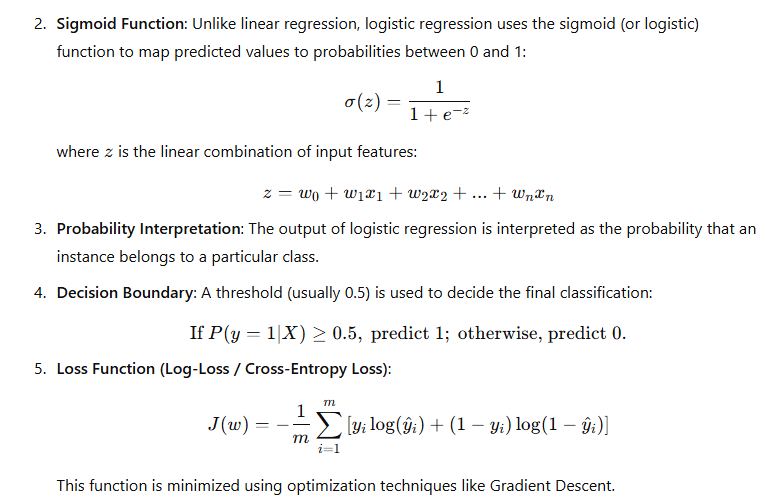

In [3]:
Image.open(os.path.join(dir_path,'pic_1.PNG'))

In [8]:
# generate the dataset

data = pd.read_csv("C:/Admin/CQF Course/Python Labs/Self Logistic Regression/data.csv")
y = data['diagnosis']
data.drop(columns = ['id','diagnosis'], inplace=True)
X = data
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size =0.2, shuffle=False,random_state=0)


accuracy of the model is 0.9736842105263158


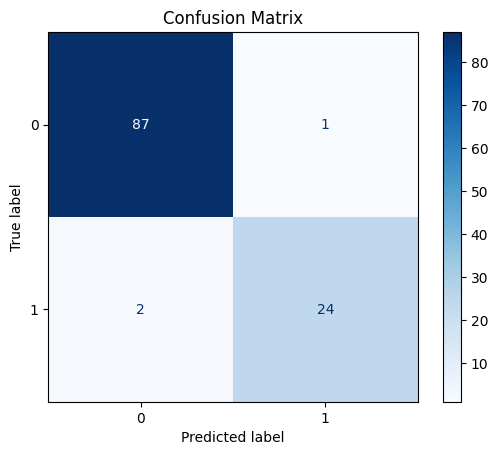

In [11]:
# train-test split


# perform logistic regression
model = Pipeline([('scaler',MinMaxScaler()),('classifier',LogisticRegression())])

model.fit(X_train,y_train)                                      # model.fit()

# coefficients of logistic regression 

# predicting the model output
y_pred = model.predict(X_test)                                  # model.predict()

# display the confusion matrix
confusion_matrix(y_test, y_pred)                                # confusion_matrix()                                

model_accuracy  = accuracy_score(y_pred,y_test)                 # accuracy_score()
print('accuracy of the model is {}'.format(model_accuracy))

# ConfusionMatrixDisplay.from_estimator()
disp = ConfusionMatrixDisplay.from_estimator(estimator = model, X= X_test, y= y_test,labels=model.classes_ , cmap='Blues')
plt.title('Confusion Matrix')
plt.show()


### Another Approach with focus on hyterparameters tuning 

In [ ]:
# model parameters 
model.get_params()                                    # model.get_params()

In [22]:
# param_grid = {'penalty':['l1','l2','elasticnet','none'],
#               'C' : np.logspace(-4,4,20),
#               'solver': ['lbfgs','newton-cg','liblinear','sag','saga'],
#               'max_iter'  : [100,1000,2500,5000]}


# Exhaustive search over specified parameter values for an estimator-create gridsearch object(i.e. simiar to pipeline object) 
param_grid = {'classifier__C' : [0.001, 0.01, 0.1, 1, 10, 100]}

grid_search = GridSearchCV(estimator = model,               # GridSearchCV()
                           param_grid = param_grid,
                           n_jobs = -1,                     # n_jobs - use all cores avaialble to machine
                           cv = 3,
                           verbose = True)

In [ ]:
best_model = grid_search.fit(X,y)
best_model.best_estimator_                                  # best_model.best_estimator_ 

Fitting 5 folds for each of 6 candidates, totalling 30 fits


Pipeline(steps=[('scaler', MinMaxScaler()),
                ('classifier', LogisticRegression(C=10))])

In [21]:
best_model.best_estimator_

Pipeline(steps=[('scaler', MinMaxScaler()),
                ('classifier', LogisticRegression(C=10))])

In [18]:
model = Pipeline([('scaler',MinMaxScaler()),('classifier',LogisticRegression(C=10))])
model.fit(X_train,y_train)                                      # model.fit()


Pipeline(steps=[('scaler', MinMaxScaler()),
                ('classifier', LogisticRegression(C=10))])

accuracy of the model is 0.9824561403508771


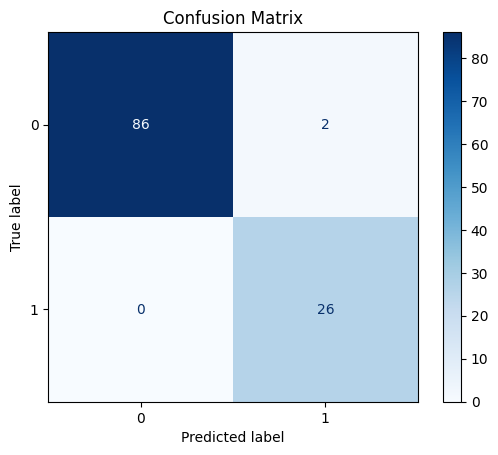

In [23]:
# predicting the model output
y_pred = model.predict(X_test)                                  # model.predict()

# display the confusion matrix
confusion_matrix(y_test, y_pred)                                # confusion_matrix()                                

model_accuracy  = accuracy_score(y_pred,y_test)                 # accuracy_score()
print('accuracy of the model is {}'.format(model_accuracy))

# ConfusionMatrixDisplay.from_estimator()
disp = ConfusionMatrixDisplay.from_estimator(estimator = model, X= X_test, y= y_test,labels=model.classes_ , cmap='Blues')
plt.title('Confusion Matrix')
plt.show()